# Cross-validation and model selection

## Outline

### This week

-   Cross-validation and model selection
-   Principal Component Regression (PCR)

### Week 3

-   Regression with regularization: Ridge & Lasso

### Week 4

-   Classification: Logistic regression, Support Vector Machines, Random forests

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Use the local data/ directory
DATA_PATH = '../../data'


def load_ames_data(features, target):
    """
    Load Ames housing data from CSV file and select features and target variable

    Parameters
    ----------
    features : list of str
        List of column names to be used as features (or predictors)
    target : str
        Column name to be used as target variable (or response)

    Returns
    -------
    X : pd.DataFrame
        DataFrame containing selected features
    y : pd.Series
        Series containing the target variable
    """
    # Load data from CSV file
    file = f'{DATA_PATH}/ames_houses.csv'
    df = pd.read_csv(file)

    # Remove extreme outliers in terms of living area or lot area
    df = df.query('LivingArea <= 350 & LotArea <= 5000')

    # Drop any missing obs in selected columns
    columns = features + [target]
    df = df.dropna(subset=columns)

    # Select features and target variable
    X = df[features]
    y = df[target]

    return X, y

***
## Optimizing hyperparameters with cross-validation

### Outline of hyperparameter tuning

- Hyperparameters: additional parameters that are **not** estimated, e.g., polynomial degree used earlier
- How do we find optimal values for such parameters?
    1. Estimate model for different values of hyperparameters
    2. Pick best-performing model

![CV split](cv_split.svg)

***
### Example: Tuning of the polynomial degree

- Same setting as earlier:
    $$
    p(x,z) = \beta_0 + \beta_1 x + \beta_2 z + \beta_3 x^2 + \beta_4 x \cdot z + \beta_5 z^2
    $$
    - $x$: `LivingArea`
    - $z$: `LotArea`

#### Automatic cross-validation with `cross_validate()`
##### Step 1: Load and pre-process Ames housing data

In [6]:
# Load Ames housing data
features = ['LivingArea', 'LotArea']
target = 'SalePrice'

X, y = load_ames_data(features, target)

##### Step 2: Perform cross-validation
- Find best polynomial degree $d = 0,\dots,5$ using K-fold CV with 10 folds
- Use [`cross_validate()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html#sklearn.model_selection.cross_validate) to compute RMSE on *both* train and test samples
- Use [`cross_val_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html) to compute RMSE *only* on test sample

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold

degrees = np.arange(10)

# Lists to store average RMSE for train and test data for all polynomial degrees
rmse_train_mean = []
rmse_test_mean = []

for d in degrees:
    # Create pipeline to transform and fit the model. Pipeline depends
    # on polynomial degree!
    if d == 0:
       # Intercept-only model
        pipe = make_pipeline(
            PolynomialFeatures(degree=d, include_bias=True),
            LinearRegression(fit_intercept=False),
        )
    else:
        # Model with polynomial terms: need to standardize features for
        # numerical stability
        pipe = make_pipeline(
            PolynomialFeatures(degree=d, include_bias=False),
            StandardScaler(),
            LinearRegression(fit_intercept=True),
        )

    rmse_train_fold = []
    rmse_test_fold = []

    # Create 10 folds
    folds = KFold(n_splits=10)

    # Iterate through all combinations of training/test data
    for itrain, itest in folds.split(X, y):
        # Extract training data for this split
        X_train = X.iloc[itrain]
        y_train = y.iloc[itrain]

        # Extract test (or validation) data for this split
        X_test = X.iloc[itest]
        y_test = y.iloc[itest]

        # Fit model on training data for given degree
        pipe.fit(X_train, y_train)

        # Predict response on train and test data
        y_train_hat = pipe.predict(X_train)
        y_test_hat = pipe.predict(X_test)

        # Compute RMSE as model fit measure
        rmse_train = root_mean_squared_error(y_train, y_train_hat)
        rmse_test = root_mean_squared_error(y_test, y_test_hat)

        # Store RMSE for current split
        rmse_train_fold.append(rmse_train)
        rmse_test_fold.append(rmse_test)

    # Store average MSE for current polynomial degree
    rmse_train_mean.append(np.mean(rmse_train_fold))
    rmse_test_mean.append(np.mean(rmse_test_fold))

# Convert to NumPy arrays
rmse_train_mean = np.array(rmse_train_mean)
rmse_test_mean = np.array(rmse_test_mean)

# Print average RMSE for all polynomial degrees
rmse_test_mean

array([78.10225405, 54.06796801, 53.7579006 , 53.52612724, 55.57874839,
       67.2402846 , 64.06836535, 84.94519901, 73.51609203, 63.72452899])

##### Step 3: Find hyperparameter with lowest RMSE

In [18]:
# Find index of polynomial degree with smallest RMSE
imin = np.argmin(rmse_test_mean)

# RMSE-minimizing polynomial degree
dmin = degrees[imin]

print(f'Polynomial degree with minimum RMSE: {dmin}')

Polynomial degree with minimum RMSE: 3


##### Step 4: Plot validation curve

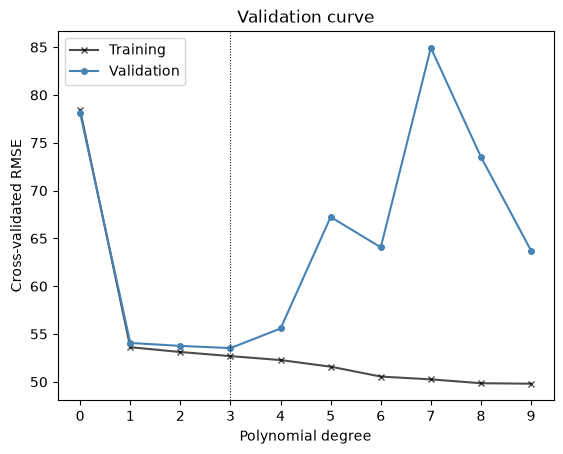

In [19]:
plt.plot(
    degrees, rmse_train_mean, c='black', marker='x', ms=4, alpha=0.7, label='Training'
)
plt.plot(degrees, rmse_test_mean, c='steelblue', marker='o', ms=4, label='Validation')
plt.xlabel('Polynomial degree')
plt.ylabel('Cross-validated RMSE')
plt.xticks(degrees)
plt.axvline(imin, ls=':', lw=0.75, c='black')
plt.title('Validation curve')
_ = plt.legend()

***
#### Automatically computing the validation curve

- Even more automated: [`validation_curve()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.validation_curve.html)
- Specify parameter to tune, parameter range, and scoring metric
- `validation_curve()` returns scores for training and test sets for all folds

In [22]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

degrees = np.arange(6)

# cross_val_score() only returns scores for test data
rmse_test_mean = []

for d in degrees:
    # Create pipeline to transform and fit the model. Pipeline depends
    # on polynomial degree!
    if d == 0:
        # Intercept-only model
        pipe = make_pipeline(
            PolynomialFeatures(degree=d, include_bias=True),
            LinearRegression(fit_intercept=False),
        )
    else:
        # Model with polynomial terms: need to standardize features for
        # numerical stability
        pipe = make_pipeline(
            PolynomialFeatures(degree=d, include_bias=False),
            StandardScaler(),
            LinearRegression(fit_intercept=True),
        )

    # Compute negative RMSE for all 10 folds
    score = cross_val_score(pipe, X, y, scoring='neg_root_mean_squared_error', cv=10)

    # Function returns NEGATIVE RMSE, correct this here!
    rmse_test_mean.append(np.mean(-score))

# Convert to NumPy array
rmse_test_mean = np.array(rmse_test_mean)

# Print average RMSE for all polynomial degrees
rmse_test_mean

array([78.10225405, 54.06796801, 53.7579006 , 53.52612724, 55.57874839,
       67.2402846 ])

In [25]:
imin = np.argmin(rmse_test_mean)
dmin = degrees[imin]

print(f'Polynomial degree with min. RMSE: {dmin}')

Polynomial degree with min. RMSE: 3


ValueError: x and y must have same first dimension, but have shapes (6,) and (10,)

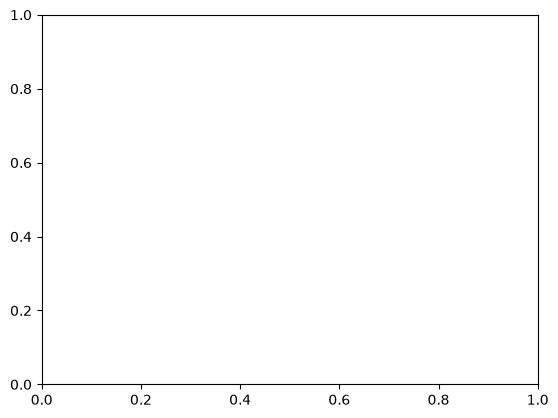

In [27]:
plt.plot(
    degrees, rmse_train_mean, c='black', marker='x', ms=4, alpha=0.7, label='Training'
)
plt.plot(degrees, rmse_test_mean, c='steelblue', marker='o', ms=4, label='Validation')
plt.xlabel('Polynomial degree')
plt.ylabel('Cross-validated RMSE')
plt.xticks(degrees)
plt.axvline(imin, ls=':', lw=0.75, c='black')
plt.title('Validation curve')
_ = plt.legend()